In [36]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, clear_output
import time

In [37]:
image = cv2.imread("img.png")
lab_image = cv2.cvtColor(image, cv2.COLOR_BGR2LAB)

pixels = lab_image.reshape((-1, 3)).astype(np.float32)

print(image.shape)

(4032, 3024, 3)


In [38]:
K = 16
MAX_ACCENT_COLORS = 4
MIN_REGION_AREA = 4
BIN_SIZE = 8

h, w = lab_image.shape[:2]
pixels = lab_image.reshape(-1, 3).astype(np.float32)

criteria = (
    cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER,
    100,
    0.2
)

bins = (pixels // BIN_SIZE).astype(np.int32)
bins = np.clip(bins, 0, 31)

bin_ids = bins[:, 0] * 1024 + bins[:, 1] * 32 + bins[:, 2]
_, inverse, counts = np.unique(
    bin_ids, return_inverse=True, return_counts=True
)

pixel_frequency = counts[inverse]

frequency_cutoff = np.percentile(pixel_frequency, 10)
rare_mask = (pixel_frequency <= frequency_cutoff).reshape(h, w)

num_labels, components, stats, _ = cv2.connectedComponentsWithStats(
    rare_mask.astype(np.uint8), connectivity=8
)

region_mask = np.zeros((h, w), dtype=bool)

for i in range(1, num_labels):
    area = stats[i, cv2.CC_STAT_AREA]
    if area >= MIN_REGION_AREA:
        region_mask |= components == i

if region_mask.mean() > 0.25:
    region_mask[:] = False
    
accent_pixels = pixels[region_mask.ravel()]
regular_pixels = pixels[~region_mask.ravel()]

accent_centers = np.empty((0, 3), dtype=np.float32)

if len(accent_pixels) >= 2:
    accent_k = min(MAX_ACCENT_COLORS, len(accent_pixels))

    _, _, accent_centers = cv2.kmeans(
        accent_pixels,
        accent_k,
        None,
        criteria,
        3,
        cv2.KMEANS_PP_CENTERS
    )

remaining_k = K - len(accent_centers)

if remaining_k > 0 and len(regular_pixels) >= remaining_k:
    _, regular_labels, regular_centers = cv2.kmeans(
        regular_pixels,
        remaining_k,
        None,
        criteria,
        3,
        cv2.KMEANS_PP_CENTERS
    )

    quantized_pixels = np.empty_like(pixels)

    quantized_pixels[~region_mask.ravel()] = regular_centers[
        regular_labels.ravel()
    ]

    if len(accent_centers):
        accent_distances = np.linalg.norm(
            accent_pixels[:, None, :] -
            accent_centers[None, :, :],
            axis=2
        )

        quantized_pixels[region_mask.ravel()] = accent_centers[
            np.argmin(accent_distances, axis=1)
        ]

    quantized_lab = np.clip(
        quantized_pixels.reshape(h, w, 3), 0, 255
    ).astype(np.uint8)

    quantized_bgr = cv2.cvtColor(
        quantized_lab, cv2.COLOR_LAB2BGR
    )
else:
    _, labels, centers = cv2.kmeans(
        pixels, K, None, criteria, 3,
        cv2.KMEANS_PP_CENTERS
    )

    quantized_lab = np.clip(
        centers[labels.ravel()].reshape(h, w, 3), 0, 255
    ).astype(np.uint8)

    quantized_bgr = cv2.cvtColor(
        quantized_lab, cv2.COLOR_LAB2BGR
    )

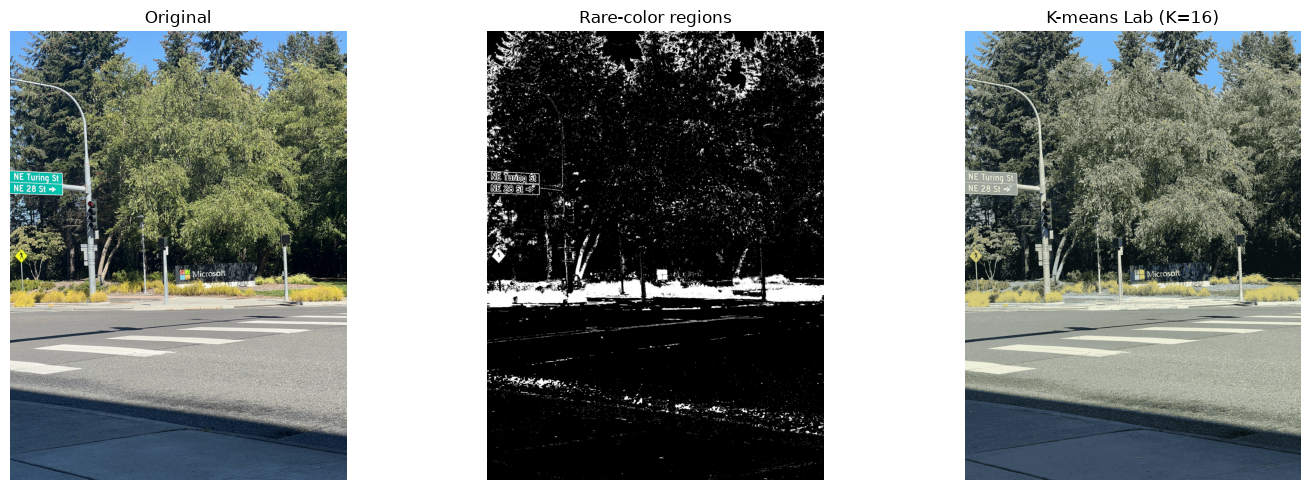

In [39]:
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
quantized_rgb = cv2.cvtColor(quantized_bgr, cv2.COLOR_BGR2RGB)
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(image_rgb)
axes[0].set_title("Original")
axes[0].axis('off')
axes[1].imshow(region_mask, cmap="gray")
axes[1].set_title("Rare-color regions")
axes[1].axis('off')
axes[2].imshow(quantized_rgb)
axes[2].set_title(f"K-means Lab (K={K})")
axes[2].axis('off')

plt.tight_layout()
plt.show()

In [40]:
gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)

blurred = cv2.GaussianBlur(
    gray,
    (0, 0),
    sigmaX=2.0
)

sobel_x = cv2.Sobel(
    blurred, cv2.CV_32F, 1, 0, ksize=3
)

sobel_y = cv2.Sobel(
    blurred, cv2.CV_32F, 0, 1, ksize=3
)

magnitude = cv2.magnitude(sobel_x, sobel_y)

edges = cv2.normalize(
    magnitude, None, 0, 255, cv2.NORM_MINMAX
).astype(np.uint8)

gradient_angle = np.arctan2(sobel_y, sobel_x)

stroke_angle = gradient_angle + np.pi / 2

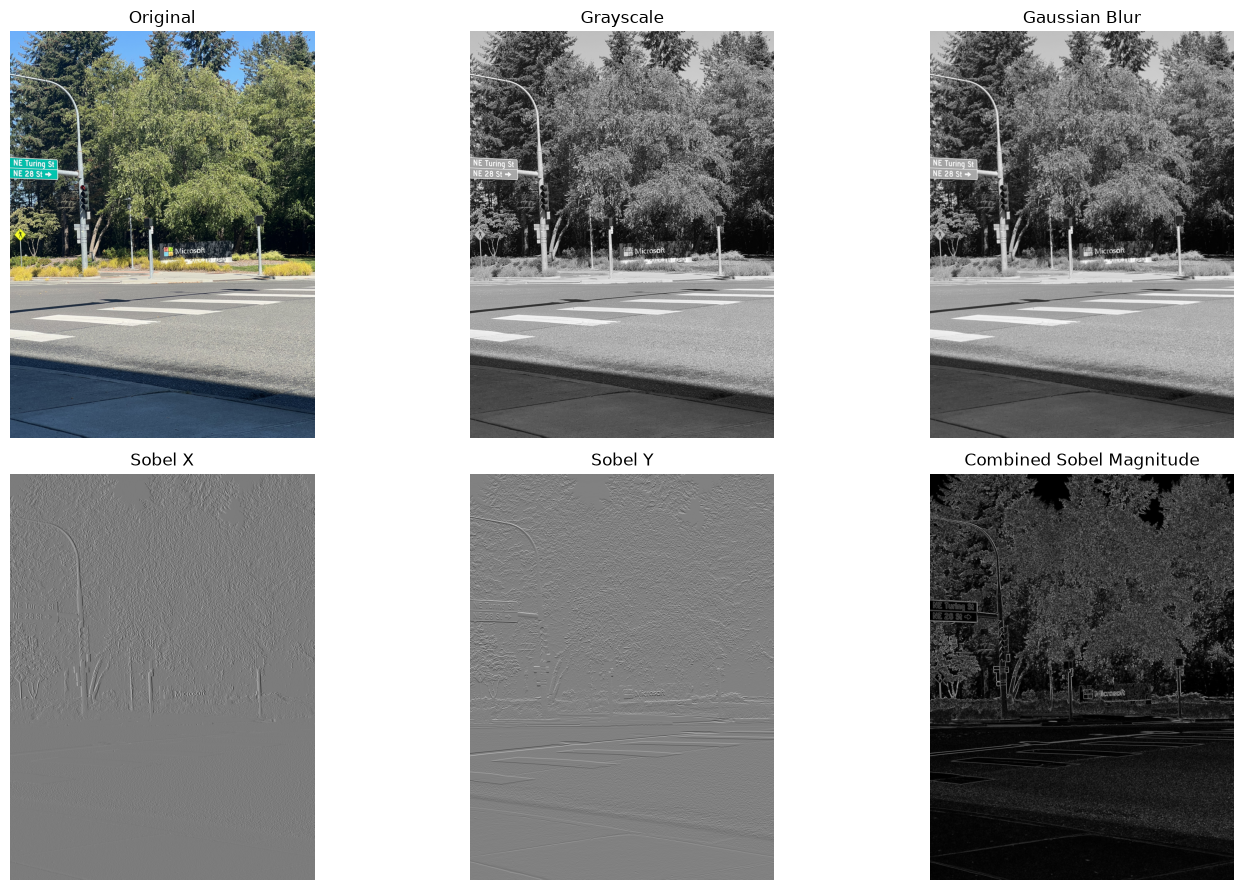

In [41]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))

axes[0, 0].imshow(image_rgb)
axes[0, 0].set_title("Original")

axes[0, 1].imshow(gray, cmap="gray")
axes[0, 1].set_title("Grayscale")

axes[0, 2].imshow(blurred, cmap="gray")
axes[0, 2].set_title("Gaussian Blur")

axes[1, 0].imshow(sobel_x, cmap="gray")
axes[1, 0].set_title("Sobel X")

axes[1, 1].imshow(sobel_y, cmap="gray")
axes[1, 1].set_title("Sobel Y")

axes[1, 2].imshow(edges, cmap="gray")
axes[1, 2].set_title("Combined Sobel Magnitude")

for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [42]:
strength = magnitude / (magnitude.max() + 1e-8)
hue = (stroke_angle % np.pi) / np.pi

hsv = np.zeros((*gray.shape, 3), dtype=np.float32)
hsv[..., 0] = hue
hsv[..., 1] = 1.0
hsv[..., 2] = strength

direction_rgb = cv2.cvtColor(
    hsv, cv2.COLOR_HSV2RGB
)

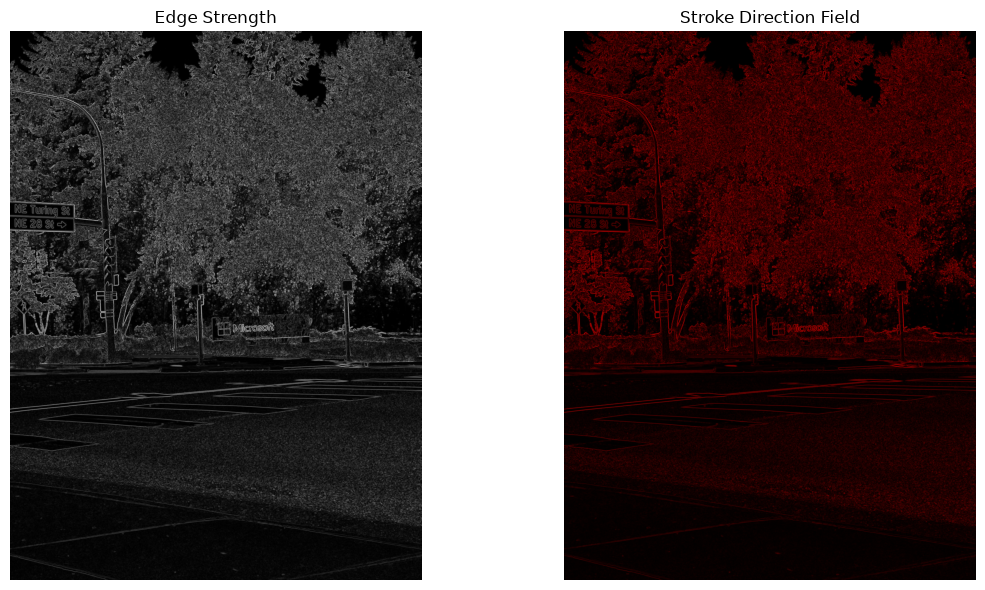

In [43]:
plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(edges, cmap="gray")
plt.title("Edge Strength")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(direction_rgb)
plt.title("Stroke Direction Field")
plt.axis("off")

plt.tight_layout()
plt.show()

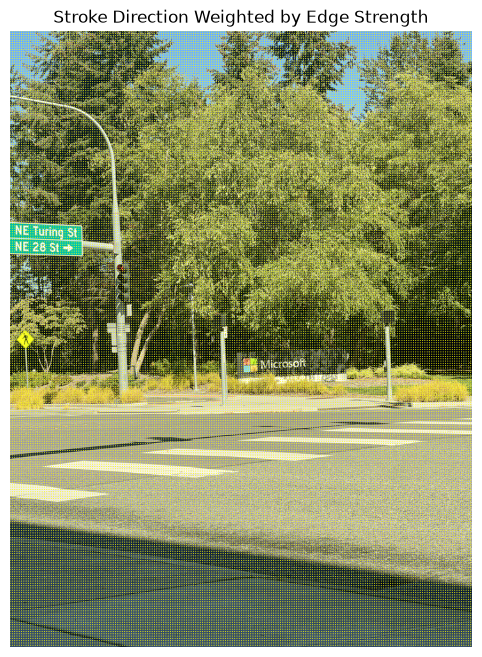

In [44]:
step = 15

strength = magnitude / (magnitude.max() + 1e-8)

y, x = np.mgrid[0:gray.shape[0]:step,
                0:gray.shape[1]:step]

angle = stroke_angle[::step, ::step]
mag = strength[::step, ::step]

U = np.cos(angle) * mag
V = -np.sin(angle) * mag

plt.figure(figsize=(12, 8))
plt.imshow(image_rgb)

plt.quiver(
    x, y, U, V,
    color="yellow",
    angles="xy",
    scale_units="xy",
    scale=0.08,
    pivot="middle"
)

plt.title("Stroke Direction Weighted by Edge Strength")
plt.axis("off")
plt.show()

In [45]:
canvas = np.ones_like(image) * 255

def draw_stroke(canvas, start_x, start_y,
                radius=3, max_length=20,
                color_threshold=25):

    h, w = canvas.shape[:2]

    reference = quantized[start_y, start_x].astype(float)

    x, y = float(start_x), float(start_y)
    angle = float(stroke_angle[start_y, start_x])

    points = []

    for _ in range(max_length):
        ix, iy = int(round(x)), int(round(y))

        if not (0 <= ix < w and 0 <= iy < h):
            break

        current = quantized[iy, ix].astype(float)
        difference = np.linalg.norm(current - reference)

        if difference > color_threshold:
            break

        points.append((ix, iy))

        local_angle = float(stroke_angle[iy, ix])

        delta = ((local_angle - angle + np.pi/2) % np.pi) - np.pi/2
        angle += 0.3 * delta

        x += np.cos(angle)
        y += np.sin(angle)

    if len(points) < 2:
        return

    color = tuple(int(v) for v in quantized_bgr[start_y, start_x][::-1])
    
    dark_color = tuple(int(v * 0.72) for v in color)

    pts = np.array(points, dtype=np.int32).reshape(-1, 1, 2)

    cv2.polylines(
        canvas, [pts], False, dark_color,
        thickness=radius * 2,
        lineType=cv2.LINE_AA
    )
    
    cv2.polylines(
        canvas, [pts], False, color,
        thickness=max(1, radius * 2),
        lineType=cv2.LINE_AA
    )

    cv2.circle(canvas, points[0], radius, color, -1,
            lineType=cv2.LINE_AA)
    cv2.circle(canvas, points[-1], radius, color, -1,
            lineType=cv2.LINE_AA)

    cv2.circle(canvas, points[0], radius, color, -1)
    cv2.circle(canvas, points[-1], radius, color, -1)

In [46]:
canvas = np.ones_like(image) * 255

rng = np.random.default_rng(42)

h, w = image.shape[:2]
short_side = min(h, w)
area_scale = ((h * w) / (512 * 512)) ** 0.3

base_passes = [
    (0.020,  800, 0.15),
    (0.012, 1200, 0.10),
    (0.006, 1800, 0.06),
    (0.003, 2500, 0.03),
]

passes = [
    (
        int(short_side * radius_frac),
        int(count * area_scale),
        int(short_side * length_frac)
    )
    for radius_frac, count, length_frac in base_passes
]

print(passes)

[(60, 2531, 453), (36, 3797, 302), (18, 5695, 181), (9, 7910, 90)]


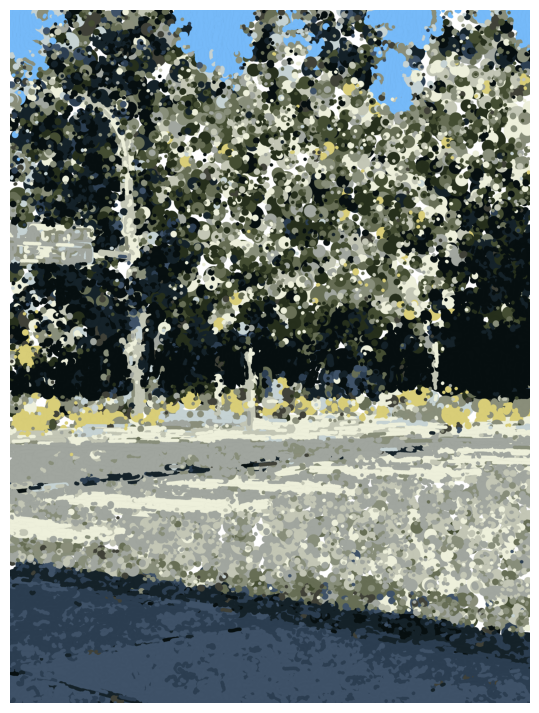

In [47]:
fig, ax = plt.subplots(figsize=(7, 9))
ax.axis("off")
artist = ax.imshow(canvas)
display(fig)
plt.close(fig)

batch_size = 20
update_delay = 0.01
stroke_number = 0

for radius, count, length in passes:
    for _ in range(count):
        x = int(rng.integers(0, w))
        y = int(rng.integers(0, h))

        draw_stroke(
            canvas,
            x, y,
            radius=radius,
            max_length=length,
            color_threshold=25
        )

        stroke_number += 1
        
        if stroke_number % batch_size == 0:
            artist.set_data(canvas)
            clear_output(wait=True)
            display(fig)
            time.sleep(update_delay)

artist.set_data(canvas)
clear_output(wait=True)
display(fig)

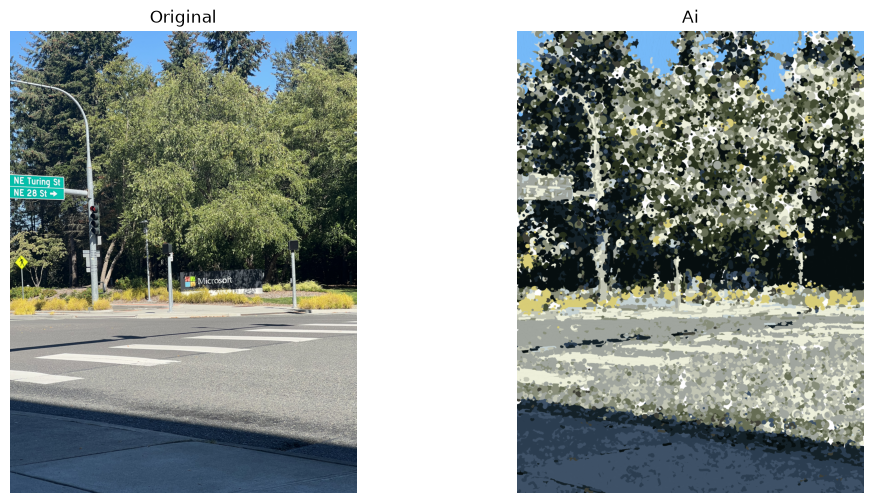

In [48]:
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

axes[0].imshow(image_rgb)
axes[0].set_title("Original")
axes[0].axis('off')
axes[1].imshow(canvas)
axes[1].set_title("Ai")
axes[1].axis('off')
plt.show()